# Введение
В ноутбуке рассматривается датасет со спектрами флуоресценции смесей катионов металлоа и гидразона L. В таблице отображена зависимость интенсивности излучения гидразона L при добалении металлов (Ag, Al, Ba, Ca и др.) от длины волны, нм.
Цель: проанализировать структуру данных, проверить на наличие ошибок, визуализировать основную зависимость.

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.io as pio

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# Для корректного отображения изображений на GitHub выбран статический рендерер "png".
pio.renderers.default = "png"
pio.templates.default = "plotly_white"

import sys
sys.path.append('..') 
from data_loader import read_spectra

df = read_spectra('../спектры.csv')


print(f"Размер таблицы: {df.shape}")
df.head()

Размер таблицы: (601, 19)


,"Длина волны, нм",Ag,Al,Ba,Ca,Cd,Ce,Co,Cr,Cu,Fe,Ga,Hg,In,K,Mg,Na,Ni,Pb
0,400.0,124.560,248.133,110.688,109.148,100.317,208.234,63.102,92.760,64.420,586.125,119.493,710.449,589.847,105.319,105.561,104.876,61.813,96.907
1,400.5,127.462,260.910,109.331,112.386,103.050,224.304,64.585,93.419,65.021,608.328,123.339,746.161,612.213,106.921,107.121,110.687,62.688,101.295
2,401.0,133.460,269.215,115.796,116.084,104.248,239.400,66.792,97.817,67.237,645.135,126.240,798.488,648.676,112.369,111.679,115.474,62.161,107.015
3,401.5,131.838,296.611,120.010,119.832,106.924,253.870,65.318,101.277,69.867,676.218,134.261,830.943,681.833,114.959,117.301,119.422,60.984,107.756
4,402.0,134.292,310.676,124.504,125.859,114.454,267.504,62.071,103.758,69.818,711.942,137.337,883.022,716.059,120.218,118.827,123.290,62.423,114.687


## Структура и целостность данных
Обзор типов данных и проверка ошибок 

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 601 entries, 0 to 600
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Длина волны, нм  601 non-null    float64
 1   Ag               601 non-null    float64
 2   Al               601 non-null    float64
 3   Ba               601 non-null    float64
 4   Ca               601 non-null    float64
 5   Cd               601 non-null    float64
 6   Ce               601 non-null    float64
 7   Co               601 non-null    float64
 8   Cr               601 non-null    float64
 9   Cu               601 non-null    float64
 10  Fe               601 non-null    float64
 11  Ga               601 non-null    float64
 12  Hg               601 non-null    float64
 13  In               601 non-null    float64
 14  K                601 non-null    float64
 15  Mg               601 non-null    float64
 16  Na               601 non-null    float64
 17  Ni               601 non-nu

## Проверка данных на наличие дубликатов

In [23]:
print(f"Количество полных дубликатов: {df.duplicated().sum()}")

Количество полных дубликатов: 0


## Метрики и выбросы
Базовая статистика на выявления аномалий 

In [24]:
df.describe()

,"Длина волны, нм",Ag,Al,Ba,Ca,Cd,Ce,Co,Cr,Cu,Fe,Ga,Hg,In,K,Mg,Na,Ni,Pb
count,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000
mean,550.000000,910.130699,2092.199940,909.562285,992.594652,805.187800,2662.486281,110.583067,676.784468,227.171522,1618.106120,1036.187539,2792.678564,2437.666722,1027.100587,968.040037,1037.537481,96.172577,937.787230
std,86.819017,518.596785,1338.025238,520.564197,573.730183,488.791674,1554.445954,69.579874,410.930958,156.440833,1543.160966,580.233552,2278.084978,1912.066160,591.191632,552.979788,589.288131,59.669796,542.370007
min,400.000000,124.560000,215.629000,109.331000,109.148000,100.317000,208.234000,21.065000,84.251000,24.505000,75.561000,119.493000,192.969000,170.073000,105.319000,105.561000,104.876000,17.569000,96.907000
25%,475.000000,376.219000,776.643000,378.779000,398.959000,307.327000,1076.543000,43.940000,261.103000,86.902000,276.738000,441.287000,794.480000,707.292000,412.665000,401.985000,427.388000,37.389000,379.098000
50%,550.000000,946.079000,2018.240000,951.431000,1042.827000,798.215000,2827.758000,97.270000,691.994000,186.206000,971.266000,1104.804000,2059.888000,1918.079000,1078.063000,1020.837000,1104.488000,87.032000,979.966000
75%,625.000000,1485.703000,3291.983000,1453.638000,1619.631000,1337.963000,4361.577000,176.499000,1096.019000,358.963000,2859.819000,1663.272000,4634.266000,4021.572000,1671.511000,1544.819000,1661.998000,146.593000,1518.461000
max,700.000000,1565.116000,4281.312000,1616.508000,1727.962000,1475.453000,4590.322000,238.192000,1286.569000,519.108000,4651.377000,1749.028000,7160.440000,6004.163000,1782.132000,1708.486000,1793.263000,205.277000,1651.454000


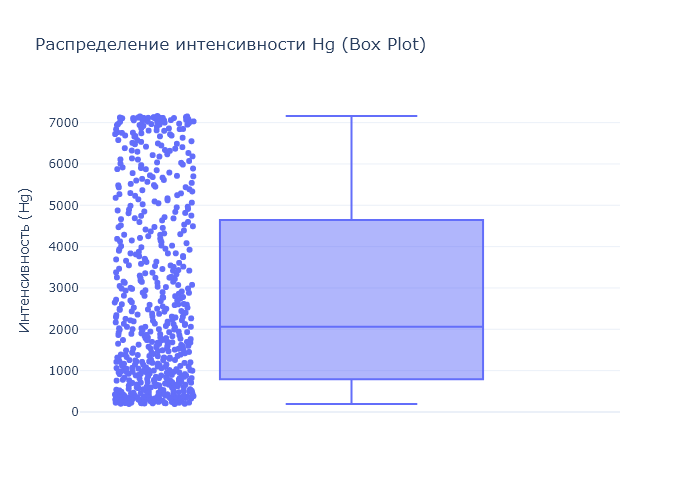

In [25]:
fig2 = px.box(
    df, 
    y="Hg", 
    title="Распределение интенсивности Hg (Box Plot)",
    labels={"Hg": "Интенсивность (Hg)"},
    points="all"
)
fig2.show()

## Визуализация
Графики для нескольких металлов, чтобы наглядно увидеть их пики при разных длинах волн.

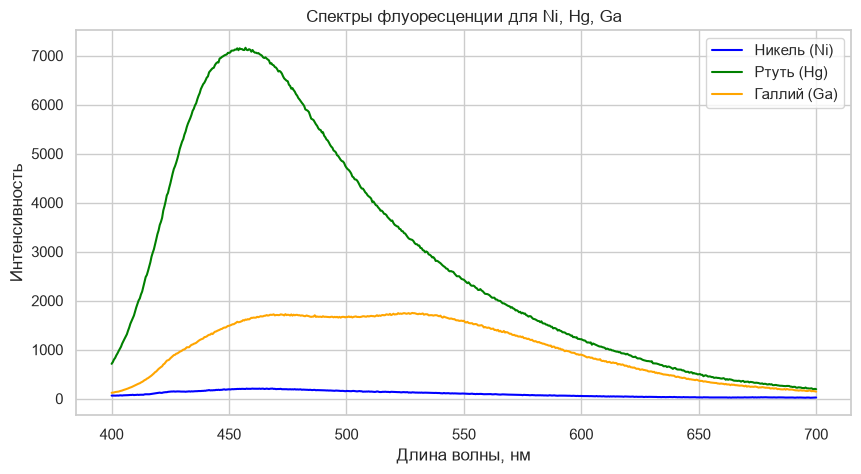

In [26]:
plt.plot(df["Длина волны, нм"], df["Ni"], label="Никель (Ni)", color="blue")
plt.plot(df["Длина волны, нм"], df["Hg"], label="Ртуть (Hg)", color="green")
plt.plot(df["Длина волны, нм"], df["Ga"], label="Галлий (Ga)", color="orange")

plt.title("Спектры флуоресценции для Ni, Hg, Ga")
plt.xlabel("Длина волны, нм")
plt.ylabel("Интенсивность")
plt.legend()
plt.show()

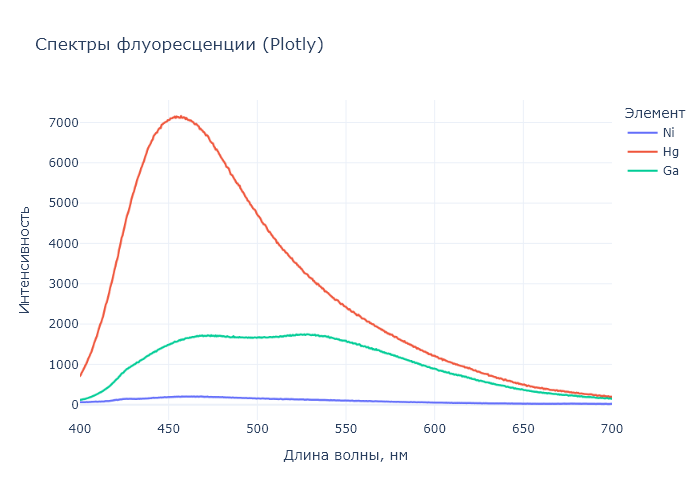

In [27]:
fig = px.line(
    df, 
    x="Длина волны, нм", 
    y=["Ni", "Hg", "Ga"],
    title="Спектры флуоресценции (Plotly)",
    labels={"value": "Интенсивность", "variable": "Элемент"}
)
fig.update_layout(hovermode="x unified")
fig.show()

## Корреляция данных
Построение матрицы корреляции, чтобы увидеть связь между элементами

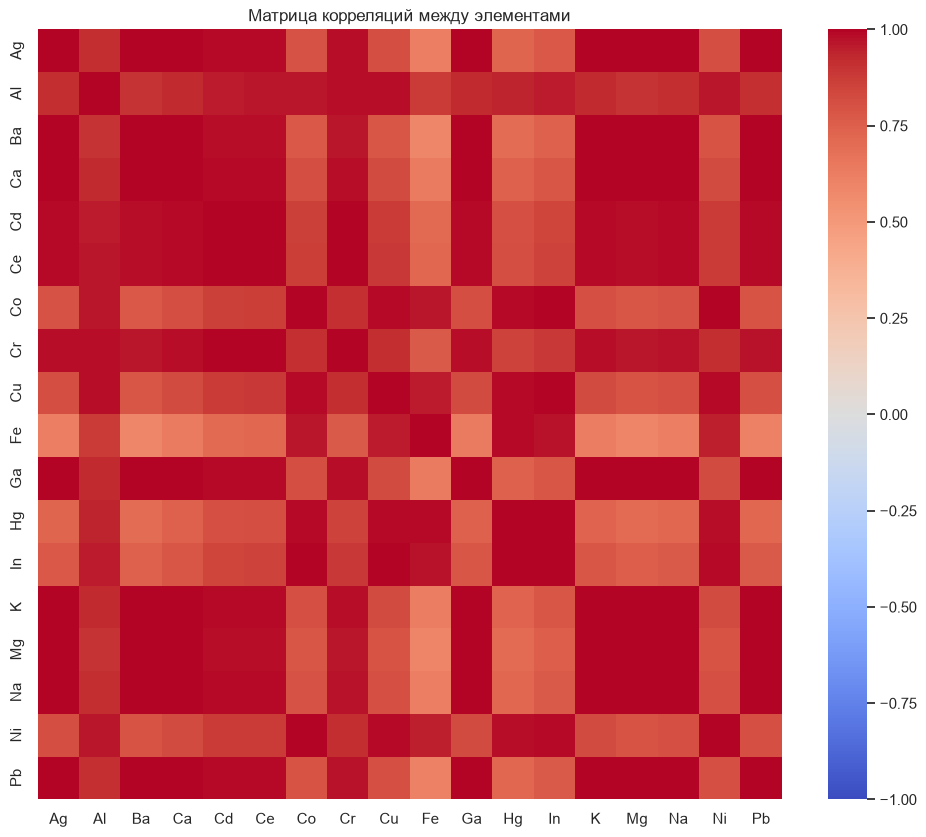

In [28]:
corr_df = df.drop(columns=["Длина волны, нм"])

plt.figure(figsize=(12, 10))
sns.heatmap(corr_df.corr(), cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций между элементами")
plt.show()

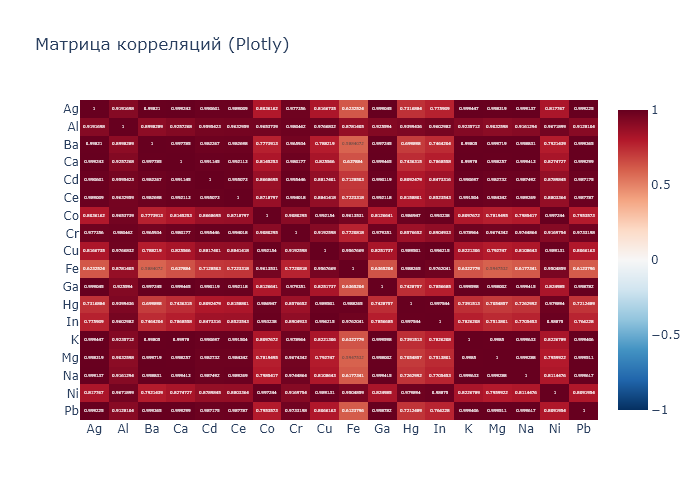

In [29]:
corr_matrix = df.drop(columns=["Длина волны, нм"]).corr()

fig3 = px.imshow(
    corr_matrix, 
    text_auto=True, 
    aspect="auto", 
    color_continuous_scale="RdBu_r",
    color_continuous_midpoint=0,
    title="Матрица корреляций (Plotly)"
)
fig3.show()

## Заключение 
Датасет содержит 601 строку и 19 столбцов (длина волны, нм + 18 катионов). Все представленные значения числовые (`float64`). Пропусков и дубликатов нет. Анализ статистики показывает, что минимальные значения интенсивности положительные. Отрицательных значений нет, что говорит о физической корректности данных. Явных выбросов не выявлено. Построенные графики для Ni, Hg и Ga наглядно демонстрируют, что разные элементы имеют разные спектральные характеристики. У них отличаются как длины волн, на которых наблюдаются пики, так и сама максимальная интенсивность. На графике видно, что пик с ртутью значительно выше чем у галлия и никеля. У галлия наблюдается бимодальный пик, что обоснуется образованием двух разных "гидразон L + Ме". Матрица корреляций показывает высокую степень связи между большинством элементов. Это может говорить о том, что элементы имеют схожую природу флуоресценции в исследуемом диапазоне длин волн. 
Данные качественные, чистые и готовы к построению моделей металл-лиганд или другого более глубокого анализа.
В ходе работы использовались две библиотеки. `matplotlib` отлично подходит для быстрой и простой статической визуализации.`Plotly` позволяет наводить мышь, объединять данные в одну подсказку и делает картинки более современными. Для отображения визуализаций данных на GitHub использовался статический формат PNG.